# Radar Verisiyle Hava Sahası Hedef Sınıflandırma
### Yapay Zeka Destekli Erken Uyarı — Uçtan Uca Yapay Zeka Projesi

---
## Aşama 1: Problem Tanımı

**Alan:** Savunma sanayi / hava savunma ve erken uyarı sistemleri

**Problem cümlesi:** Radarın ölçtüğü hız, irtifa, radar kesit alanı, manevra ve pervane imzası bilgilerinden, tespit edilen hava hedefinin türünü tahmin et.

**Hedef değişken (y):** `hedef_turu` → `kus` / `mini_iha` / `sabit_kanat_iha` / `helikopter_ucak`

**Problem türü:** Çok sınıflı sınıflandırma (`DecisionTreeClassifier`)

**Gerekçe:** Küçük insansız hava araçları günümüzde havalimanları, enerji tesisleri ve askeri bölgeler için ciddi bir güvenlik riski oluşturuyor. Bu araçlar boyut, hız ve irtifa bakımından kuşlara çok benzediği için radar operatörleri sık sık yanlış alarmla karşılaşıyor. Gerçek bir tehdidi gözden kaçırmak da her kuşa alarm vermek de pahalıya mal oluyor. Radar ölçümlerinden hedef türünü otomatik olarak tahmin eden bir model, operatörün yükünü azaltır, tepki süresini kısaltır ve hava sahası güvenliğini artırır.

---
## Aşama 2: Veri Toplama ve Hazırlama

**Veri kaynağı:** Gerçek radar verileri gizli olduğundan, bu proje için gerçekçi fiziksel aralıklara dayanan **sentetik** bir veri seti oluşturuldu (203 satır, 5 özellik + 1 hedef). Gerçek hayattaki gibi içinde eksik değerler, sensör hata kodları, yazım tutarsızlıkları ve tekrar eden kayıtlar bulunuyor.

> **Çalıştırma:** Ham veri `data/raw/radar_hedefleri.csv` konumunda. VS Code'da proje kökündeki `.venv` yorumlayıcısını seçip hücreleri sırayla çalıştırın.

In [ ]:
# Gerekli kütüphaneler
import pandas as pd
import numpy as np
from pathlib import Path

# Proje klasörleri (notebook, notebooks/ klasöründen çalıştırılır)
PROJE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
HAM_VERI = PROJE / "data" / "raw" / "radar_hedefleri.csv"
TEMIZ_VERI = PROJE / "data" / "processed" / "radar_hedefleri_temiz.csv"

# Veriyi oku
df = pd.read_csv(HAM_VERI)

# İlk 5 satıra ve boyuta bakalım
print("Veri boyutu (satır, sütun):", df.shape)
df.head()

,hiz_kmh,irtifa_m,rcs_m2,manevra_skoru,pervane_imzasi,hedef_turu
0,35.0,387.0,0.0202,7.9,1,mini_iha
1,218.3,5579.0,1.0806,1.4,1,sabit_kanat_iha
2,78.1,798.0,0.0097,3.9,0,kus
3,75.2,675.0,0.0127,6.9,0,kus
4,416.1,6011.0,10.3941,1.3,1,helikopter_ucak


### Veri Sözlüğü

| Sütun | Tip | Anlamı | Rol |
|---|---|---|---|
| `hiz_kmh` | Sayısal | Hedefin hızı (km/saat) | Özellik (X) |
| `irtifa_m` | Sayısal | Yerden yükseklik (metre) | Özellik (X) |
| `rcs_m2` | Sayısal | Radar kesit alanı: hedefin radarda ne kadar "büyük" göründüğü (m²) | Özellik (X) |
| `manevra_skoru` | Sayısal | Dakikadaki ani yön değişimi sayısı | Özellik (X) |
| `pervane_imzasi` | Kategorik (0/1) | Radarda dönen pervane izi (mikro-Doppler) var mı? 1 = var | Özellik (X) |
| `hedef_turu` | Kategorik | Hedefin türü: kus, mini_iha, sabit_kanat_iha, helikopter_ucak | **Hedef (y)** |

### Sorunları tespit edelim

In [ ]:
# 1) Sütun tipleri
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   hiz_kmh         199 non-null    float64
 1   irtifa_m        200 non-null    float64
 2   rcs_m2          200 non-null    float64
 3   manevra_skoru   201 non-null    float64
 4   pervane_imzasi  203 non-null    int64  
 5   hedef_turu      201 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 9.6+ KB


In [ ]:
# 2) Her sütunda kaç eksik değer var?
print(df.isnull().sum())

hiz_kmh           4
irtifa_m          3
rcs_m2            3
manevra_skoru     2
pervane_imzasi    0
hedef_turu        2
dtype: int64


In [ ]:
# 3) Hedef sütunundaki etiketler tutarlı mı?
print(df["hedef_turu"].value_counts(dropna=False))

hedef_turu
kus                54
sabit_kanat_iha    49
mini_iha           48
helikopter_ucak    46
NaN                 2
KUS                 1
 mini_iha           1
Kus                 1
Mini_IHA            1
Name: count, dtype: int64


In [ ]:
# 4) İmkânsız değerler var mı? (hız ve irtifa negatif olamaz)
print("Negatif hız sayısı  :", (df["hiz_kmh"] < 0).sum())
print("Negatif irtifa sayısı:", (df["irtifa_m"] < 0).sum())

# 5) Tekrar eden satır var mı?
print("Tekrar eden satır    :", df.duplicated().sum())

Negatif hız sayısı  : 2
Negatif irtifa sayısı: 3
Tekrar eden satır    : 3


### Temizleme

In [ ]:
# Adım 1: Tekrar eden satırları sil
df = df.drop_duplicates()

# Adım 2: Etiket yazımlarını düzelt ("KUS", " mini_iha" -> "kus", "mini_iha")
df["hedef_turu"] = df["hedef_turu"].str.strip().str.lower()

# Adım 3: Etiketi olmayan satırları sil (hedefi bilinmeyen satırdan model öğrenemez)
df = df.dropna(subset=["hedef_turu"])

# Adım 4: İmkânsız değerleri (sensör hata kodları) eksik değere çevir
df.loc[df["irtifa_m"] < 0, "irtifa_m"] = np.nan
df.loc[df["hiz_kmh"] < 0, "hiz_kmh"] = np.nan

# Adım 5: Sayısal sütunlardaki eksikleri o sütunun medyanıyla doldur
for sutun in ["hiz_kmh", "irtifa_m", "rcs_m2", "manevra_skoru"]:
    df[sutun] = df[sutun].fillna(df[sutun].median())

In [ ]:
# Kontrol: Temizlik sonrası durum
print("Yeni boyut:", df.shape)
print("Kalan eksik değer:", df.isnull().sum().sum())
print()
print(df["hedef_turu"].value_counts())

Yeni boyut: (198, 6)
Kalan eksik değer: 0

hedef_turu
kus                55
mini_iha           50
sabit_kanat_iha    48
helikopter_ucak    45
Name: count, dtype: int64


In [ ]:
# Temiz veriyi kaydet (sonraki aşamalarda bunu kullanacağız)
TEMIZ_VERI.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(TEMIZ_VERI, index=False)
print("Kaydedildi:", TEMIZ_VERI.name)

Kaydedildi: radar_hedefleri_temiz.csv


## Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [ ]:
import matplotlib.pyplot as plt

# Temizlenmiş veriyi oku
df = pd.read_csv(TEMIZ_VERI)

print("Boyut:", df.shape)
df.describe().round(2)

Boyut: (198, 6)


,hiz_kmh,irtifa_m,rcs_m2,manevra_skoru,pervane_imzasi
count,198.00,198.00,198.00,198.00,198.00
mean,124.45,2047.42,2.10,4.12,0.59
std,110.17,2187.66,4.60,3.05,0.49
min,12.80,37.00,0.00,0.20,0.00
25%,44.42,355.25,0.01,1.90,0.00
50%,72.25,862.50,0.10,3.10,1.00
75%,174.38,3843.75,1.61,6.12,1.00
max,447.70,7872.00,23.72,11.90,1.00


In [ ]:
# Her hedef türünün ortalama ölçümleri
df.groupby("hedef_turu")[["hiz_kmh", "irtifa_m", "rcs_m2", "manevra_skoru"]].mean().round(2)

,hiz_kmh,irtifa_m,rcs_m2,manevra_skoru
hedef_turu,,,,
helikopter_ucak,283.02,4116.72,8.29,1.37
kus,54.01,556.68,0.04,7.29
mini_iha,44.75,305.94,0.06,5.09
sabit_kanat_iha,139.54,3629.65,0.79,2.07


In [ ]:
# Her hedef türünde pervane imzası görülme oranı (0-1 arası)
print(df.groupby("hedef_turu")["pervane_imzasi"].mean().round(2))
print()
print(df["hedef_turu"].value_counts())

hedef_turu
helikopter_ucak    0.51
kus                0.09
mini_iha           0.92
sabit_kanat_iha    0.90
Name: pervane_imzasi, dtype: float64

hedef_turu
kus                55
mini_iha           50
sabit_kanat_iha    48
helikopter_ucak    45
Name: count, dtype: int64


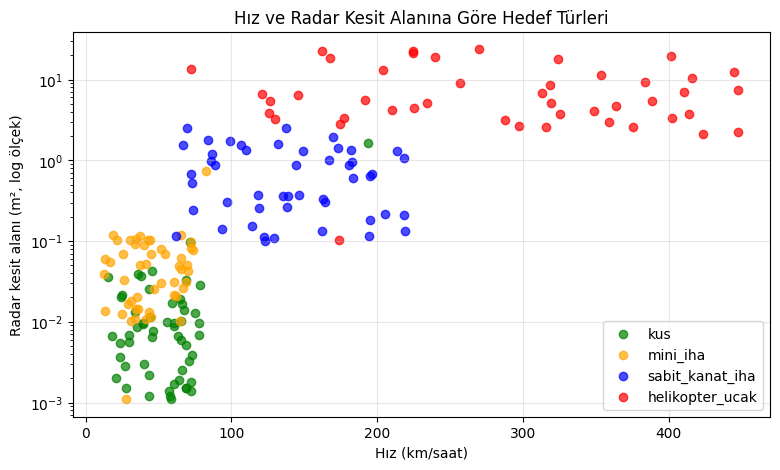

In [ ]:
# Her hedef türüne bir renk verelim
renkler = {"kus": "green", "mini_iha": "orange",
           "sabit_kanat_iha": "blue", "helikopter_ucak": "red"}

plt.figure(figsize=(9, 5))
for tur, renk in renkler.items():
    alt = df[df["hedef_turu"] == tur]
    plt.scatter(alt["hiz_kmh"], alt["rcs_m2"], label=tur, color=renk, alpha=0.7)

plt.yscale("log")   # RCS değerleri 0.001 ile 25 arasında; log ölçek hepsini görünür yapar
plt.title("Hız ve Radar Kesit Alanına Göre Hedef Türleri")
plt.xlabel("Hız (km/saat)")
plt.ylabel("Radar kesit alanı (m², log ölçek)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

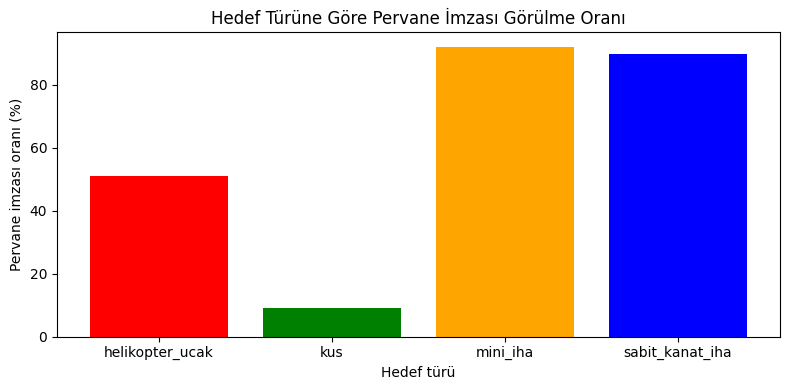

In [ ]:
oran = df.groupby("hedef_turu")["pervane_imzasi"].mean() * 100

plt.figure(figsize=(8, 4))
plt.bar(oran.index, oran.values, color=[renkler[t] for t in oran.index])
plt.title("Hedef Türüne Göre Pervane İmzası Görülme Oranı")
plt.xlabel("Hedef türü")
plt.ylabel("Pervane imzası oranı (%)")
plt.tight_layout()
plt.show()

### Keşif Bulguları

1. **Hız ve radar kesit alanı, büyük hedefleri küçüklerden net biçimde ayırıyor.** Helikopter/uçaklar ortalama 283 km/s hız ve 8 m² RCS ile en sağ üstte, sabit kanatlı İHA'lar ise ortada (140 km/s, 0.8 m²) kümeleniyor.
2. **Kuş ve mini İHA birbirine çok benziyor.** İkisi de yavaş (45–55 km/s), alçakta uçuyor ve radarda çok küçük görünüyor. Grafikte bu iki sınıf iç içe geçmiş durumda; modelin en çok zorlanacağı yer burası.
3. **Pervane imzası, kuşu İHA'dan ayıran en belirleyici özellik.** Mini İHA'ların %92'sinde pervane izi görülürken kușlarda bu oran sadece %9.
4. **Manevra skoru da yardımcı oluyor.** Kuşlar ani yön değiştirdiği için ortalama manevra skoru en yüksek sınıf (7.3), helikopter/uçaklar ise en düzgün uçan sınıf (1.4).
5. **Birkaç aykırı nokta var** (örneğin yavaş görünen birkaç uçak). Bunlar, eksik hız değerlerini medyanla doldurmamızdan kaynaklanıyor olabilir; modelin bazı hatalarını bu açıklayabilir.


## Aşama 4: Model Kurma ve Eğitme

In [ ]:
# Modelin bakacağı bilgiler (özellikler)
X = df[["hiz_kmh", "irtifa_m", "rcs_m2", "manevra_skoru", "pervane_imzasi"]]

# Modelin tahmin edeceği şey (hedef)
y = df["hedef_turu"]

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)

X boyutu: (198, 5)
y boyutu: (198,)


In [ ]:
from sklearn.model_selection import train_test_split

# Verinin %80'i eğitim, %20'si test için ayrılıyor.
# stratify=y: her sınıftan eğitim ve test kümesine aynı oranda örnek düşmesini sağlar.
# random_state=42: her çalıştırmada aynı bölünmenin olması için.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Eğitim verisi :", X_train.shape, y_train.shape)
print("Test verisi   :", X_test.shape, y_test.shape)

Eğitim verisi : (158, 5) (158,)
Test verisi   : (40, 5) (40,)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# max_depth=4: ağaç en fazla 4 soru derinliğine iner.
# Bu sınır, modelin veriyi ezberlemesini (aşırı öğrenme) önler.
model = DecisionTreeClassifier(max_depth=4, random_state=42)

# Eğitim: model, eğitim verisindeki örneklerden kurallar öğreniyor
model.fit(X_train, y_train)

print("Model eğitildi")

Model eğitildi


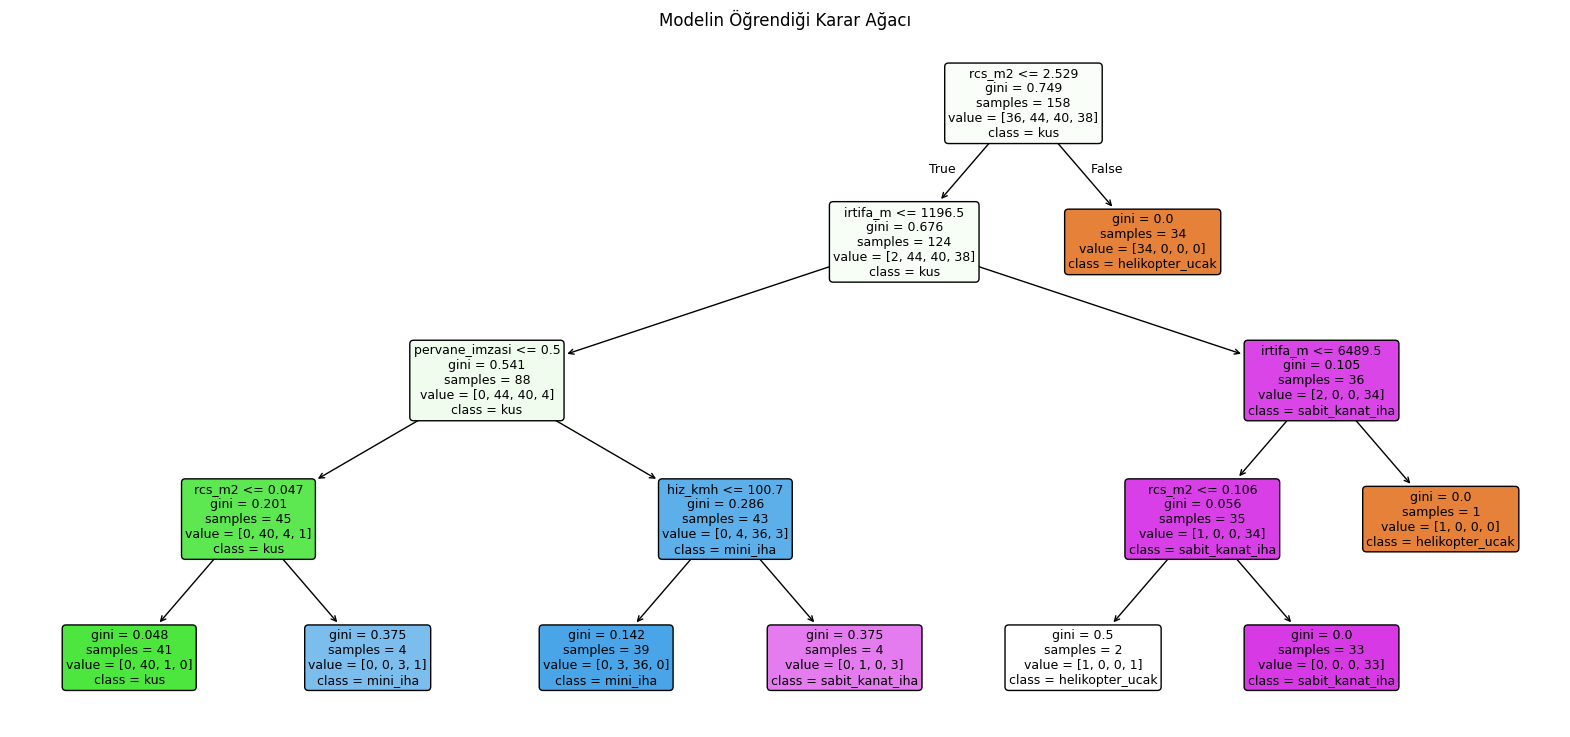

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 9))
plot_tree(model, feature_names=X.columns, class_names=model.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title("Modelin Öğrendiği Karar Ağacı")
plt.show()

### Model Seçim Gerekçesi

Problemimiz sayı değil sınıf tahmini (kuş / mini İHA / sabit kanatlı İHA / helikopter-uçak) olduğu için regresyon yerine sınıflandırma modeli olan **Karar Ağacı (DecisionTreeClassifier)** seçildi. Karar ağacı, "RCS 2.5 m²'den küçük mü?", "pervane imzası var mı?" gibi evet/hayır sorularıyla karar verdiği için, bir radar operatörünün düşünme biçimine çok benziyor ve kararlarının nedeni kolayca açıklanabiliyor. Savunma gibi hataların pahalı olduğu alanlarda modelin **neden** o kararı verdiğini görebilmek büyük bir avantaj. Ağacın derinliği 4 ile sınırlandırılarak modelin veriyi ezberlemesi engellendi.

---
## Aşama 5: Tahmin ve Değerlendirme

In [ ]:
from sklearn.metrics import accuracy_score

# Model test verisini daha önce hiç görmedi; şimdi tahmin ediyor
tahminler = model.predict(X_test)

dogruluk = accuracy_score(y_test, tahminler)
print(f"Test doğruluğu: %{dogruluk*100:.1f}")
print(f"{len(y_test)} test örneğinden {(tahminler == y_test).sum()} tanesi doğru tahmin edildi.")

Test doğruluğu: %95.0
40 test örneğinden 38 tanesi doğru tahmin edildi.


In [ ]:
# Eğitim ve test başarısı birbirine yakınsa model ezberlememiş demektir
egitim_puani = model.score(X_train, y_train)
test_puani = model.score(X_test, y_test)

print(f"Eğitim doğruluğu: %{egitim_puani*100:.1f}")
print(f"Test doğruluğu  : %{test_puani*100:.1f}")

Eğitim doğruluğu: %95.6
Test doğruluğu  : %95.0


In [ ]:
# Satırlar gerçek sınıf, sütunlar modelin tahmini.
# Köşegendeki sayılar doğru tahminler, dışındakiler hatalar.
pd.crosstab(y_test, tahminler, rownames=["Gerçek"], colnames=["Tahmin"])

Tahmin,helikopter_ucak,kus,mini_iha,sabit_kanat_iha
Gerçek,,,,
helikopter_ucak,8,0,0,1
kus,0,10,1,0
mini_iha,0,0,10,0
sabit_kanat_iha,0,0,0,10


In [ ]:
# Radarın yeni tespit ettiği 5 hayali hedef
yeni_hedefler = pd.DataFrame({
    "hiz_kmh":        [45,   55,    180,  350,  60],
    "irtifa_m":       [150,  300,   3000, 5000, 200],
    "rcs_m2":         [0.03, 0.008, 0.9,  12.0, 0.06],
    "manevra_skoru":  [2.5,  9.0,   1.5,  0.8,  6.0],
    "pervane_imzasi": [1,    0,     1,    0,    0],
})

# Tahmin ve modelin kendinden ne kadar emin olduğu
yeni_tahmin = model.predict(yeni_hedefler)
guven = model.predict_proba(yeni_hedefler).max(axis=1) * 100

sonuc = yeni_hedefler.copy()
sonuc["tahmin"] = yeni_tahmin
sonuc["guven_%"] = guven.round(0)
sonuc

,hiz_kmh,irtifa_m,rcs_m2,manevra_skoru,pervane_imzasi,tahmin,guven_%
0,45,150,0.030,2.5,1,mini_iha,92.0
1,55,300,0.008,9.0,0,kus,98.0
2,180,3000,0.900,1.5,1,sabit_kanat_iha,100.0
3,350,5000,12.000,0.8,0,helikopter_ucak,100.0
4,60,200,0.060,6.0,0,mini_iha,75.0


### Tahmin Sonuçlarının Yorumu

İlk 4 örnekte model mantıklı ve yüksek güvenli tahminler yaptı. 5. örnek ise ilginç: pervane imzası olmayan, manevrası yüksek bu hedef büyük ihtimalle **iri bir kuş** (örneğin leylek veya kartal). Ancak radar kesit alanı 0.047 m²'den biraz büyük olduğu için model onu **mini İHA** olarak sınıflandırdı. Modelin bu tahminde kendinden daha az emin olması (%75) da bunu gösteriyor.

### Değerlendirme Notu: Model güvenilir mi?

- **Başarı:** Model test verisinde **%95 doğruluk** elde etti; 40 örnekten 38'ini doğru bildi.
- **Aşırı öğrenme yok:** Eğitim doğruluğu (%95.6) ile test doğruluğu (%95) neredeyse aynı. Model veriyi ezberlememiş, gerçekten genel kurallar öğrenmiş. Bunda ağaç derinliğini 4 ile sınırlamamızın payı var.
- **Hatalar:** 1 kuş mini İHA sanıldı, 1 helikopter/uçak da sabit kanatlı İHA sanıldı. Keşif aşamasında öngördüğümüz gibi en zor ayrım kuş ile mini İHA arasında.
- **Zayıf yönler:**
  1. Veri **sentetik** ve sadece 198 satır; gerçek radar verisinde gürültü çok daha fazla olacağı için başarı muhtemelen düşer.
  2. Model kuş/İHA ayrımında büyük ölçüde tek bir RCS eşiğine güveniyor; iri kuşlar bu yüzden yanlış sınıflandırılabiliyor (5. örnek).
  3. Model **manevra skorunu hiç kullanmadı**, oysa keşif aşamasında kuşların daha çok manevra yaptığını görmüştük.
- **Olası iyileştirmeler:** Daha fazla ve gerçek veri toplamak; kanat çırpma frekansı gibi yeni özellikler eklemek; Random Forest gibi birden fazla ağacı birleştiren modeller denemek; savunma açısından bir İHA'yı kuş sanmak daha tehlikeli olduğu için bu hatayı özellikle azaltmaya odaklanmak.

---
## Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

Radar operatörünün ölçüm değerlerini girdiği ve anında hedef türü, güven oranı ve önerilen işlemi gördüğü küçük bir uygulama.

In [ ]:
# Her hedef türü için okunur ad ve operatöre önerilecek işlem
ACIKLAMALAR = {
    "kus":             ("KUŞ",                "Tehdit değil. Alarm gerekmiyor, izlemeye devam edilebilir."),
    "mini_iha":        ("MİNİ İHA (drone)",   "DİKKAT! İzinsiz drone olabilir. Operatörü uyar ve hedefi yakından izle."),
    "sabit_kanat_iha": ("SABİT KANATLI İHA",  "Kimlik doğrulaması yap: Bu bölgede uçuş izni olan bir İHA mı?"),
    "helikopter_ucak": ("HELİKOPTER / UÇAK",  "İnsanlı hava aracı. Uçuş planı ve transponder bilgisiyle karşılaştır."),
}

def tahmin_et(hiz, irtifa, rcs, manevra, pervane):
    """Radar ölçümlerini alır, hedef türünü ve modelin güvenini döndürür."""
    girdi = pd.DataFrame([[hiz, irtifa, rcs, manevra, pervane]], columns=X.columns)
    tur = model.predict(girdi)[0]
    guven = model.predict_proba(girdi).max() * 100
    return tur, guven

def sayi_al(soru):
    """Kullanıcı geçerli bir sayı girene kadar tekrar sorar (virgülü de kabul eder)."""
    while True:
        try:
            return float(input(soru).replace(",", "."))
        except ValueError:
            print("  Uyarı: Lütfen bir sayı gir (örnek: 45 veya 0.03).")

def radar_araci():
    print("=" * 55)
    print("   RADAR HEDEF SINIFLANDIRMA ARACI")
    print("=" * 55)
    hiz     = sayi_al("Hız (km/saat)                     : ")
    irtifa  = sayi_al("İrtifa (metre)                    : ")
    rcs     = sayi_al("Radar kesit alanı (m²)            : ")
    manevra = sayi_al("Manevra skoru (yön değişimi / dk) : ")
    cevap   = input("Pervane imzası var mı? (e/h)      : ").strip().lower()
    pervane = 1 if cevap.startswith("e") else 0

    tur, guven = tahmin_et(hiz, irtifa, rcs, manevra, pervane)
    ad, oneri = ACIKLAMALAR[tur]

    print("-" * 55)
    print(f"Tespit edilen hedef büyük olasılıkla bir {ad}.")
    print(f"   Modelin güveni: %{guven:.0f}")
    if guven < 80:
        print("   Uyarı: Güven düşük, sonucu bir operatör kontrol etmeli.")
    print(f"Öneri: {oneri}")
    print("=" * 55)

radar_araci()

   RADAR HEDEF SINIFLANDIRMA ARACI


---
## Sonraki Adım: Modüler Kod ve Geliştirmeler

Bu defter, projenin keşif ve prototip aşamasıdır. Üretime yakın sürümü `src/radar_classifier/` paketindedir ve şu iyileştirmeleri içerir:

- **Veri sızıntısı giderildi:** Eksik değerler artık tüm veri yerine yalnızca eğitim verisinin medyanıyla, sklearn `Pipeline` içinde dolduruluyor.
- **Model karşılaştırması:** Karar Ağacı, Lojistik Regresyon, Random Forest ve Gradient Boosting 5 katlı tabakalı çapraz doğrulamayla karşılaştırılıyor; en iyisi otomatik seçiliyor.
- **Savunmaya özel metrik:** Drone'u kuş sanmak en pahalı hata olduğu için `mini_iha` duyarlılığı (recall) ayrıca raporlanıyor.
- **Uygulama:** Komut satırı aracı (`python -m radar_classifier.predict`) ve Streamlit web arayüzü (`streamlit run app/streamlit_app.py`).

```bash
python -m radar_classifier.train
```